# Multi-object tracking on MOT17: SORT, ByteTrack, OC-SORT and BoT-SORT

A robot that navigates among people needs more than per-frame detections: it needs to know
that the pedestrian at the left edge *now* is the same one it saw a second ago, so it can
estimate their velocity, predict their path and keep a safe distance. That is
**multi-object tracking (MOT)**: detect every object in every frame and give each physical
object one persistent identity.

This notebook builds the classic **tracking-by-detection** pipeline step by step on two real
MOT17 sequences (a static camera, MOT17-02, and a hand-held moving camera, MOT17-05):

1. detect people with **YOLO26s** (Ultralytics, COCO-pretrained, not fine-tuned on MOT17),
2. predict where each track will be with a **Kalman filter**,
3. associate predictions and detections with the **Hungarian algorithm** on IoU,
4. compare a from-scratch **SORT** with **ByteTrack** (low-score association),
   **OC-SORT** and **BoT-SORT** (camera-motion compensation, optional ReID),
5. test whether a general-purpose foundation model (**DINOv3**) can serve as BoT-SORT's
   appearance (re-identification) model, next to a dedicated person-ReID network,
6. score everything with the official MOTChallenge metrics **MOTA, IDF1 and HOTA**, using a
   NumPy implementation that is cross-checked against the reference TrackEval code.

**What you'll learn**
- why low-confidence detections help (ByteTrack) and why camera motion breaks IoU matching
  (BoT-SORT's GMC),
- how MOTA, IDF1 and HOTA weigh detection errors against identity errors,
- how to run any Ultralytics tracker on cached detections for a fair, fast comparison,
- what makes an embedding useful for re-identification (and why generic features fall short),
- the `model.track()` API and its gotchas (explicit `tracker=`, `persist=True`).

**Prerequisites:** project 03 (object detection) helps; `make data-06_tracking` downloaded the
data. The full benchmark (both sequences, YOLO26n/s, eight tracker variants) was produced by
`projects/06_tracking/scripts/run_mot_benchmark.py`; its results are loaded in the
**Results** section. Runtime of this notebook: about 1 minute on an RTX 5060 Laptop GPU.

## Setup

Imports, the standard `cvlab.device.setup()` (seeds, device, versions) and repo-relative paths.
The tracking helpers live in `projects/06_tracking/scripts/`:
`motlib.py` (MOT I/O, metrics, SORT, tracker runner) and `trackviz.py` (figures).
We set `YOLO_AUTOINSTALL=false` *before* importing Ultralytics so it can never pip-install
packages behind our back.

In [1]:
# --- Setup: imports, device, paths and plotting style ---
# Project helpers are imported from projects/06_tracking/scripts (added to sys.path).
import logging
import os
import sys
import time
from pathlib import Path

os.environ["YOLO_AUTOINSTALL"] = "false"  # never pip-install at runtime

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

import cvlab.device
import cvlab.io
import cvlab.metrics
import cvlab.viz

device = cvlab.device.setup(seed=0)
cvlab.viz.set_style()

PROJECT = "06_tracking"
ROOT = cvlab.io.repo_root()
sys.path.insert(0, str(cvlab.io.project_dir(PROJECT) / "scripts"))
import motlib as ml  # noqa: E402
import trackviz as tv  # noqa: E402
from ultralytics import YOLO  # noqa: E402
from ultralytics.utils import LOGGER  # noqa: E402

LOGGER.setLevel(logging.WARNING)  # keep Ultralytics quiet (it prints absolute paths)
MOT_DIR = cvlab.io.data_dir("mot17")
CFG_DIR = cvlab.io.project_dir(PROJECT) / "configs"
RESULTS = cvlab.io.project_dir(PROJECT) / "results"
WEIGHTS = cvlab.io.weights_dir("ultralytics")
print("data   :", MOT_DIR.relative_to(ROOT))
print("configs:", CFG_DIR.relative_to(ROOT))

python 3.12.16 | torch 2.11.0+cu128 (CUDA 12.8) | torchvision 0.26.0+cu128 | numpy 2.5.4 | opencv 5.0.0
device: cuda | GPU: NVIDIA GeForce RTX 5060 Laptop GPU (7.53 GB, sm_120)


data   : data/mot17
configs: projects/06_tracking/configs


## 1. The data: MOT17

MOT17 (Milan et al. 2016) is the standard pedestrian-tracking benchmark. Every train sequence
ships `img1/*.jpg`, `seqinfo.ini` and `gt/gt.txt` with one row per box:

`frame, id, x_left, y_top, width, height, consider_flag, class, visibility`

Two details of the **official protocol** matter for correct numbers:

* only rows with `class = 1` (pedestrian) and `consider_flag = 1` are scored;
* rows of *distractor* classes (2 person on vehicle, 7 static person, 8 distractor,
  12 reflection) are ignored: a tracker box that matches one of them (IoU >= 0.5) is
  deleted before scoring, so it is neither a true nor a false positive.

GT boxes are **amodal**: they cover the whole person even when partly occluded, while a
detector only sees the visible part. That alone caps the achievable IoU in crowded scenes.

In [2]:
# --- Load both sequences and summarise their ground truth ---
# MOT17-02: static camera, 1080p, 30 fps. MOT17-05: hand-held moving camera, VGA, 14 fps.
seqs = {name: ml.load_sequence(MOT_DIR / name) for name in ["MOT17-02-FRCNN", "MOT17-05-FRCNN"]}
camera = {"MOT17-02-FRCNN": "static", "MOT17-05-FRCNN": "moving (hand-held)"}
rows = []
for name, s in seqs.items():
    gt = s.gt()
    scored = (gt[:, 7] == ml.PEDESTRIAN) & (gt[:, 6] != 0)
    rows.append({
        "sequence": name, "resolution": f"{s.width}x{s.height}", "fps": s.frame_rate,
        "frames": s.length, "camera": camera[name],
        "pedestrian ids": len(np.unique(gt[scored, 1])), "scored GT boxes": int(scored.sum()),
        "ignored GT rows": int((~scored).sum()),
    })
display(pd.DataFrame(rows).set_index("sequence"))

,resolution,fps,frames,camera,pedestrian ids,scored GT boxes,ignored GT rows
sequence,,,,,,,
MOT17-02-FRCNN,1920x1080,30.0,600,static,62,18581,11422
MOT17-05-FRCNN,640x480,14.0,837,moving (hand-held),133,6917,1096


Let us look at one frame of each sequence. Scored pedestrians are drawn in a colour per
identity; ignored rows (distractors, static people, vehicles, zero-marked) in grey.

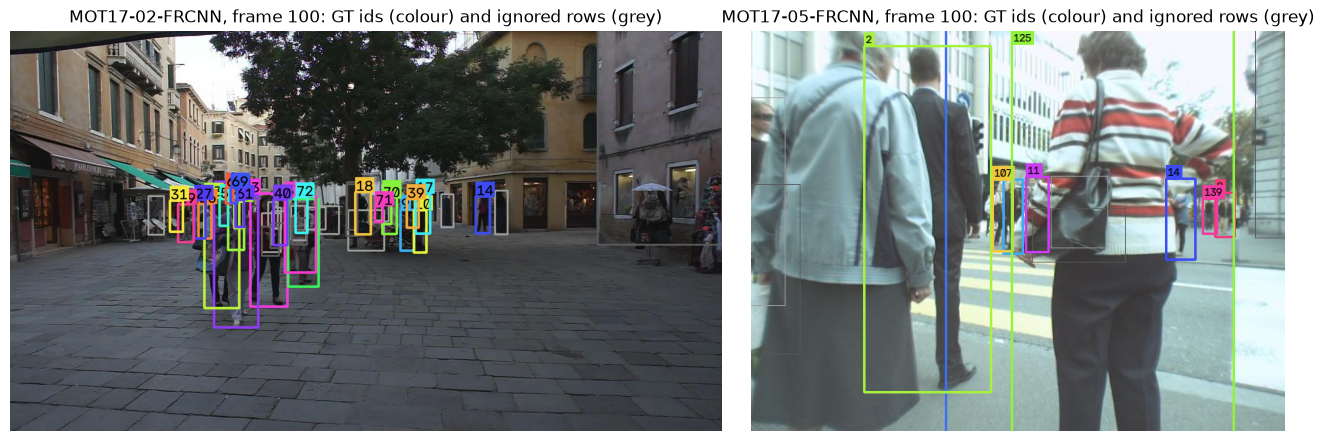

In [3]:
# --- Visualise the ground truth: scored pedestrians vs ignored rows ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={"width_ratios": [16 / 9, 4 / 3]})
for ax, name in zip(axes, seqs):
    s, t = seqs[name], 100
    gt = s.gt()
    ax.imshow(tv.draw_gt(s.frame(t), gt[gt[:, 0] == t]))
    ax.set_title(f"{name}, frame {t}: GT ids (colour) and ignored rows (grey)")
    ax.axis("off")
cvlab.viz.savefig(fig, PROJECT, "mot17_gt")
plt.show()

## 2. Tracking-by-detection in four steps

For every frame $t$:

1. **Detect**: boxes $d_j$ with confidence $s_j$.
2. **Predict**: each existing track $i$ has a Kalman state
   $\mathbf{x} = [c_x, c_y, w, h, \dot c_x, \dot c_y, \dot w, \dot h]^\top$ and a covariance $P$.
   A constant-velocity model predicts $\hat{\mathbf{x}} = F\mathbf{x}$,
   $\hat P = F P F^\top + Q$.
3. **Associate**: build a cost matrix $C_{ij} = 1 - \mathrm{IoU}(\hat b_i, d_j)$ and solve the
   linear assignment $\min_{\pi} \sum_i C_{i\pi(i)}$ with the Hungarian algorithm; pairs with
   too little overlap are rejected (gating).
4. **Update / manage**: matched tracks get a Kalman update
   $K = \hat P H^\top (H \hat P H^\top + R)^{-1}$,
   $\mathbf{x} = \hat{\mathbf{x}} + K(\mathbf{z} - H\hat{\mathbf{x}})$; unmatched detections start
   new tracks; tracks unmatched for longer than a buffer are deleted.

Everything hinges on step 1, so we start with the detector.

### Step 1: detection with YOLO26s

We keep boxes down to confidence **0.1** (far below the usual 0.25). ByteTrack uses those weak
boxes, and every tracker below gets *the same cached detections*, so differences between
trackers are purely due to association.

In [4]:
# --- Detect people in every frame of MOT17-05 with YOLO26s (fp16, native 640 px) ---
# stream=True yields one Results object per frame without keeping all of them in memory.
seq = seqs["MOT17-05-FRCNN"]
gt05 = seq.gt()
det_model = YOLO(str(WEIGHTS / "yolo26s.pt"))
fr, xyxy, conf = [], [], []
with cvlab.device.track_vram() as mem:
    t0 = time.perf_counter()
    for r in det_model.predict(source=str(seq.root / seq.img_dir), stream=True, conf=0.1,
                               classes=[0], imgsz=640, quantize=16, device=0, verbose=False):
        b = r.boxes.cpu().numpy()  # xyxy in original pixels, conf, cls
        fr.append(np.full(len(b), int(Path(r.path).stem)))  # frame number from file name
        xyxy.append(b.xyxy)
        conf.append(b.conf)
    det_seconds = time.perf_counter() - t0
dets = ml.DetectionCache(np.concatenate(fr), np.concatenate(xyxy), np.concatenate(conf))
print(f"{len(dets.conf)} person boxes, {len(dets.conf) / seq.length:.1f} per frame")
print(f"{seq.length} frames in {det_seconds:.1f} s = {seq.length / det_seconds:.1f} FPS "
      f"(incl. JPEG decoding and model warm-up), peak VRAM {mem.peak_mb:.0f} MiB")

8042 person boxes, 9.6 per frame
837 frames in 5.2 s = 162.0 FPS (incl. JPEG decoding and model warm-up), peak VRAM 72 MiB


### Are low-confidence boxes worth keeping?

Match every detection to the scored GT of its frame (greedy, IoU >= 0.5) and look at the
confidence of true vs false positives. If a good share of the boxes between 0.1 and 0.25 are
real people (typically partly occluded ones), then throwing them away creates gaps in tracks:
the observation behind **ByteTrack**.

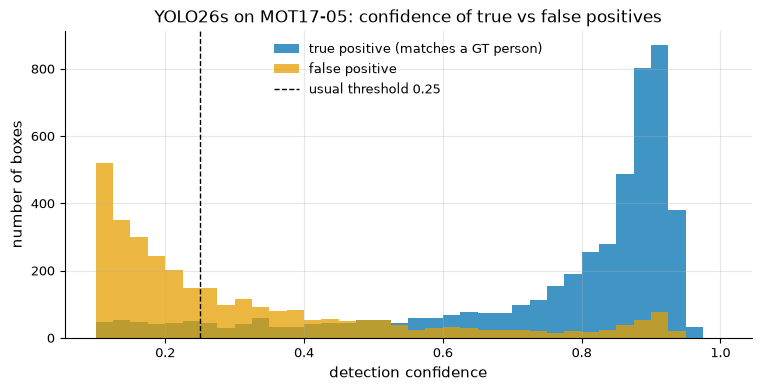

boxes with 0.1 <= conf < 0.25: 2046, of which 13.7% are true positives
boxes with conf >= 0.25      : 5996, of which 76.7% are true positives


In [5]:
# --- Confidence histogram of true vs false positive detections (IoU >= 0.5 to scored GT) ---
scored05 = gt05[(gt05[:, 7] == ml.PEDESTRIAN) & (gt05[:, 6] != 0)]
is_tp = np.zeros(len(dets.conf), dtype=bool)
for t in range(1, seq.length + 1):
    m = np.flatnonzero(dets.frame == t)
    g = scored05[scored05[:, 0] == t]
    is_tp[m] = cvlab.metrics.match_detections(dets.xyxy[m], dets.conf[m], ml.xywh_to_xyxy(g[:, 2:6]))
low = (dets.conf >= 0.1) & (dets.conf < 0.25)
bins = np.linspace(0.1, 1.0, 37)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.hist(dets.conf[is_tp], bins=bins, alpha=0.75, label="true positive (matches a GT person)")
ax.hist(dets.conf[~is_tp], bins=bins, alpha=0.75, label="false positive")
ax.axvline(0.25, color="k", ls="--", lw=1, label="usual threshold 0.25")
ax.set_xlabel("detection confidence")
ax.set_ylabel("number of boxes")
ax.set_title("YOLO26s on MOT17-05: confidence of true vs false positives")
ax.legend()
plt.show()
print(f"boxes with 0.1 <= conf < 0.25: {low.sum()}, of which {is_tp[low].mean():.1%} are true positives")
print(f"boxes with conf >= 0.25      : {(~low).sum()}, of which {is_tp[~low].mean():.1%} are true positives")

### Step 2: the Kalman filter bridges occlusions

`ml.KalmanBoxFilter` is a 30-line constant-velocity filter on $(c_x, c_y, w, h)$. Its process
and measurement noise scale with the box height (as in DeepSORT/ByteTrack), so it is equally
confident for near (large) and far (small) people. Below we feed it the GT box centre of one
pedestrian, *withhold* 15 frames to simulate an occlusion, and plot the prediction with its
$\pm 2\sigma$ band: the uncertainty grows while no measurement arrives and collapses when the
person reappears.

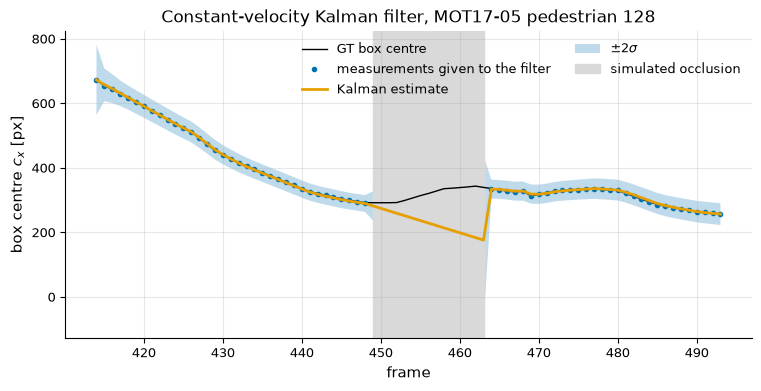

error at the end of the gap: 163.3 px; 2-sigma there: 260.0 px


In [6]:
# --- Kalman filter on one GT trajectory with a simulated 15-frame occlusion ---
ids, counts = np.unique(scored05[:, 1], return_counts=True)
pid = int(ids[np.argmax(counts)])  # the longest pedestrian track
traj = scored05[scored05[:, 1] == pid]
traj = traj[np.argsort(traj[:, 0])][:80]
z = np.column_stack([traj[:, 2] + traj[:, 4] / 2, traj[:, 3] + traj[:, 5] / 2, traj[:, 4], traj[:, 5]])
gap = np.zeros(len(z), dtype=bool)
gap[35:50] = True  # no measurement in these frames
kf = ml.KalmanBoxFilter(z[0])
est, sigma = [z[0][0]], [np.sqrt(kf.P[0, 0])]
for k in range(1, len(z)):
    kf.predict()
    if not gap[k]:
        kf.update(z[k])
    est.append(kf.x[0])
    sigma.append(np.sqrt(kf.P[0, 0]))
est, sigma, f = np.array(est), np.array(sigma), traj[:, 0]
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(f, z[:, 0], "k-", lw=1, label="GT box centre")
ax.plot(f[~gap], z[~gap, 0], "o", ms=3, label="measurements given to the filter")
ax.plot(f, est, lw=2, label="Kalman estimate")
ax.fill_between(f, est - 2 * sigma, est + 2 * sigma, alpha=0.25, label=r"$\pm 2\sigma$")
ax.axvspan(f[35], f[49], color="0.85", label="simulated occlusion")
ax.set_xlabel("frame")
ax.set_ylabel(r"box centre $c_x$ [px]")
ax.set_title(f"Constant-velocity Kalman filter, MOT17-05 pedestrian {pid}")
ax.legend(ncol=2)
plt.show()
print(f"error at the end of the gap: {abs(est[49] - z[49, 0]):.1f} px; "
      f"2-sigma there: {2 * sigma[49]:.1f} px")

### Step 3: SORT from scratch

`ml.SimpleSORT` (about 60 lines) is SORT (Bewley et al. 2016): Kalman prediction, Hungarian
matching on IoU with a 0.3 gate, new tracks from unmatched boxes with confidence >= 0.25,
deletion after 30 missed frames, and output only for tracks matched in the current frame
after 3 hits. No low-score boxes, no camera-motion model, no appearance.

`ml.run_tracker` feeds cached detections frame by frame to any object with an
`update(detections, image)` method and returns MOTChallenge rows
`(frame, id, x, y, w, h, score)`. The metrics are explained in section 4.

In [7]:
# --- Run the from-scratch SORT on the cached YOLO26s detections and score it ---
sort_rows, sort_timing = ml.run_tracker(ml.SimpleSORT(), dets, seq.length)
res = ml.evaluate(gt05, sort_rows, seq.length)
print(f"SORT (scratch): HOTA {100 * res['HOTA']:.1f} | MOTA {100 * res['MOTA']:.1f} | "
      f"IDF1 {100 * res['IDF1']:.1f} | ID switches {res['IDSW']} | "
      f"{sort_timing['tracker_fps']:.0f} FPS (tracker only, CPU)")

SORT (scratch): HOTA 43.8 | MOTA 46.8 | IDF1 58.1 | ID switches 160 | 2659 FPS (tracker only, CPU)


### Step 4: ByteTrack, OC-SORT and BoT-SORT

* **ByteTrack** (Zhang et al. 2022) associates in two stages: first tracks against
  high-score boxes ($s \ge 0.25$, IoU fused with the score), then the *remaining* tracks
  against low-score boxes ($0.1 < s < 0.25$, plain IoU). Weak boxes may extend an existing track
  but never start a new one, so they recover occluded people without adding false tracks.
  Our ablation `bytetrack_no_low.yaml` sets the low threshold equal to the high one, which
  switches the second stage off.
* **OC-SORT** (Cao et al. 2023) corrects the Kalman state with the observations seen before and
  after an occlusion and adds a velocity-direction consistency term to the cost.
* **BoT-SORT** (Aharon et al. 2022) adds **global motion compensation (GMC)**. When the camera
  moves, every box shifts in the image even if the person stands still, and the Kalman
  prediction lands in the wrong place. GMC estimates a 2D affine warp
  $A_t = [M\,|\,\mathbf{b}]$ between consecutive frames (sparse optical flow + RANSAC on
  background corners) and applies it to the predicted state:
  $\hat{\mathbf{c}} \leftarrow M\hat{\mathbf{c}} + \mathbf{b}$ (and $M$ to the velocity and
  covariance). `gmc_method: none` turns it off.

All configs are in `projects/06_tracking/configs/` (copies of the Ultralytics 8.4.204 defaults
plus the ablations). `ml.make_tracker` builds the Ultralytics tracker class from a YAML file.

In [8]:
# --- Run every tracker on the SAME cached detections (fair comparison of association) ---
# BoT-SORT's GMC needs the frame itself, so run_tracker loads it (decode time is not counted).
variants = {
    "SORT (scratch)": "sort_scratch",
    "ByteTrack w/o low-score stage": CFG_DIR / "bytetrack_no_low.yaml",
    "ByteTrack": CFG_DIR / "bytetrack.yaml",
    "OC-SORT": CFG_DIR / "ocsort.yaml",
    "BoT-SORT, no GMC": CFG_DIR / "botsort_no_gmc.yaml",
    "BoT-SORT, GMC": CFG_DIR / "botsort.yaml",
}
outputs, table = {}, {}
for label, cfg in variants.items():
    tracker = ml.make_tracker(str(cfg))
    rows_t, timing = ml.run_tracker(tracker, dets, seq.length,
                                    frame_loader=lambda t: cv2.imread(str(seq.frame_path(t))))
    outputs[label] = rows_t
    table[label] = {**ml.summary_row(ml.evaluate(gt05, rows_t, seq.length)),
                    "tracker FPS": round(timing["tracker_fps"], 1)}
cols = ["HOTA", "DetA", "AssA", "MOTA", "IDF1", "IDSW", "Frag", "CLR_FP", "CLR_FN", "tracker FPS"]
live_df = pd.DataFrame(table).T[cols]
display(live_df)

,HOTA,DetA,AssA,MOTA,IDF1,IDSW,Frag,CLR_FP,CLR_FN,tracker FPS
SORT (scratch),43.76,44.59,43.34,46.75,58.13,160.0,184.0,969.0,2554.0,2718.5
ByteTrack w/o low-score stage,44.14,43.58,45.01,47.40,60.19,100.0,150.0,881.0,2657.0,2994.2
ByteTrack,43.58,43.22,44.28,45.73,58.62,109.0,134.0,1057.0,2588.0,2758.6
OC-SORT,42.77,43.63,42.20,47.61,58.19,96.0,146.0,910.0,2618.0,1549.4
"BoT-SORT, no GMC",44.43,44.73,44.45,47.75,59.16,103.0,143.0,998.0,2513.0,2813.7
"BoT-SORT, GMC",45.45,45.93,45.29,49.43,61.19,82.0,138.0,1008.0,2408.0,283.5


## 3. The one-liner: `model.track()`

In an application you would not cache detections; Ultralytics wraps detection + tracking in
`model.track()`. Two gotchas:

* **always pass `tracker=` explicitly**: since Ultralytics 8.4 the default config is
  `tracktrack.yaml`, not ByteTrack;
* for a **folder of images** use `persist=True`: with `persist=False` the tracker is reset
  whenever the source path changes, which for an image sequence means on every frame.

The tracker inside `model.track()` receives exactly the boxes we cached above, so the tracks
are the same, with one subtle difference worth knowing: Ultralytics' `Results` object **clips
boxes to the image**, while the tracker's Kalman state (and MOT17's amodal GT boxes) may extend
past the border. For people entering or leaving the frame, clipping lowers the IoU with the GT.
We check that clipping our cached-detection output reproduces `model.track()` exactly. The
timing now includes JPEG decoding, pre-processing, inference and tracking.

In [9]:
# --- End-to-end detection + ByteTrack with model.track() on MOT17-05 ---
track_model = YOLO(str(WEIGHTS / "yolo26s.pt"))  # fresh model = fresh tracker state
e2e = []
t0 = time.perf_counter()
for r in track_model.track(source=str(seq.root / seq.img_dir), tracker="bytetrack.yaml",
                           persist=True, stream=True, conf=0.1, classes=[0], imgsz=640,
                           quantize=16, device=0, verbose=False):
    if r.boxes.id is not None:  # None until the first track is confirmed
        t = int(Path(r.path).stem)
        for tid, b, c in zip(r.boxes.id.cpu().numpy(), r.boxes.xyxy.cpu().numpy(),
                             r.boxes.conf.cpu().numpy()):
            e2e.append((t, int(tid), b[0], b[1], b[2] - b[0], b[3] - b[1], c))
e2e_seconds = time.perf_counter() - t0
e2e = np.round(np.asarray(e2e, dtype=np.float64), 2)
res_e2e = ml.evaluate(gt05, e2e, seq.length)
res_clip = ml.evaluate(gt05, ml.clip_rows(outputs["ByteTrack"], seq.width, seq.height), seq.length)
print(f"model.track(..., tracker='bytetrack.yaml'): {seq.length / e2e_seconds:.1f} FPS end to end")
for name, r in [("model.track()", res_e2e), ("cached dets + ByteTrack, clipped to the image", res_clip)]:
    print(f"  {name:48s} MOTA {100 * r['MOTA']:.2f}  IDF1 {100 * r['IDF1']:.2f}  IDSW {r['IDSW']}")
print(f"  {'cached dets + ByteTrack, not clipped':48s} MOTA {live_df.loc['ByteTrack', 'MOTA']:.2f}  "
      f"IDF1 {live_df.loc['ByteTrack', 'IDF1']:.2f}  IDSW {live_df.loc['ByteTrack', 'IDSW']}")

model.track(..., tracker='bytetrack.yaml'): 191.5 FPS end to end
  model.track()                                    MOTA 44.83  IDF1 58.12  IDSW 107
  cached dets + ByteTrack, clipped to the image    MOTA 44.83  IDF1 58.12  IDSW 107
  cached dets + ByteTrack, not clipped             MOTA 45.73  IDF1 58.62  IDSW 109.0


## 4. How the metrics work

All three metrics first match GT boxes to tracker boxes inside each frame (IoU >= 0.5 for
CLEAR/Identity), then differ in how they treat *identity*.

* **MOTA** (CLEAR MOT, Bernardin & Stiefelhagen 2008)
  $$\mathrm{MOTA} = 1 - \frac{\mathrm{FN} + \mathrm{FP} + \mathrm{IDSW}}{\mathrm{GT}}$$
  An ID switch costs as much as *one* missed box, so MOTA is dominated by detection quality.
* **IDF1** (Ristani et al. 2016) first assigns each GT trajectory to at most one predicted
  trajectory for the **whole video** (bipartite matching maximising co-occurring frames), then
  $$\mathrm{IDF1} = \frac{2\,\mathrm{IDTP}}{2\,\mathrm{IDTP} + \mathrm{IDFP} + \mathrm{IDFN}}$$
  A track that swaps identity halfway loses half of its frames: IDF1 measures how long
  identities are preserved.
* **HOTA** (Luiten et al. 2020) balances both:
  $$\mathrm{HOTA}_\alpha = \sqrt{\mathrm{DetA}_\alpha \cdot \mathrm{AssA}_\alpha},\qquad
  \mathrm{DetA} = \frac{|TP|}{|TP| + |FN| + |FP|},\qquad
  \mathrm{AssA} = \frac{1}{|TP|}\sum_{c \in TP} \frac{|TPA(c)|}{|TPA(c)| + |FNA(c)| + |FPA(c)|}$$
  averaged over localisation thresholds $\alpha = 0.05, \dots, 0.95$. AssA asks, for every
  correct match, how well the whole predicted trajectory overlaps the whole GT trajectory.

`motlib` implements all three following TrackEval line by line (including its quirks, e.g. a
frame without any tracker box does not break the "tracked in the previous frame" state), and
`tests/test_p06_mot_metrics.py` checks it against TrackEval on synthetic sequences. The
benchmark script re-scores every real tracker file with TrackEval as well (Results section).

The **identity timeline** below makes ID switches visible: one row per GT pedestrian, a grey
bar where the person is present, coloured segments for the tracker id matched to it, and a
black x at every ID switch.

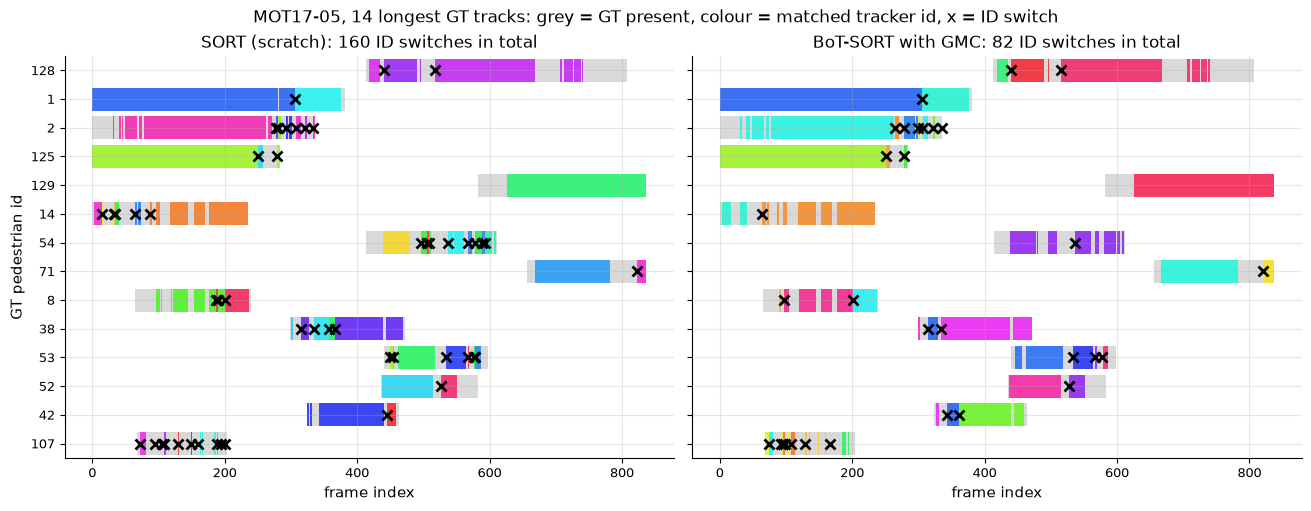

In [10]:
# --- Identity timelines: which tracker id covers each GT pedestrian over time ---
data_sort = ml.prepare_mot17(gt05, outputs["SORT (scratch)"], seq.length)
data_bot = ml.prepare_mot17(gt05, outputs["BoT-SORT, GMC"], seq.length)
clr_sort = ml.clear_metrics(data_sort, return_matches=True)
clr_bot = ml.clear_metrics(data_bot, return_matches=True)
ids, counts = np.unique(scored05[:, 1], return_counts=True)
show = ids[np.argsort(-counts)][:14].astype(int)  # the 14 longest-lived pedestrians
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
tv.plot_identity_timeline(axes[0], clr_sort["matches"], scored05, show, clr_sort["idsw_events"],
                          title=f"SORT (scratch): {clr_sort['IDSW']} ID switches in total")
tv.plot_identity_timeline(axes[1], clr_bot["matches"], scored05, show, clr_bot["idsw_events"],
                          title=f"BoT-SORT with GMC: {clr_bot['IDSW']} ID switches in total")
axes[1].set_ylabel("")
fig.suptitle("MOT17-05, 14 longest GT tracks: grey = GT present, colour = matched tracker id, x = ID switch")
cvlab.viz.savefig(fig, PROJECT, "identity_timeline")
plt.show()

### What an identity switch looks like

We take the first ID switch of BoT-SORT on a pedestrian and crop the frames around it:
the last frame matched with the old id, and the frame where a new id takes over.
Typical causes: an occlusion longer than the motion model can bridge, two people crossing,
or a missed detection while the camera turns.

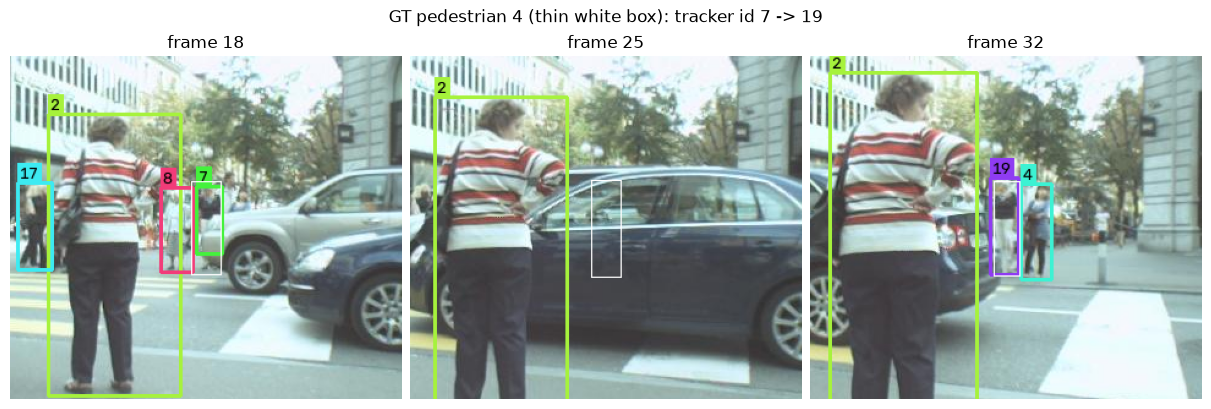

the switch happens 14 frame(s) after the last match with id 7


In [11]:
# --- Crops around one identity switch (BoT-SORT with GMC) ---
ev = clr_bot["idsw_events"][0]  # (frame_index, gt_id, old_tracker_id, new_tracker_id)
t_sw, gid, old_id, new_id = (int(v) for v in ev)
m = clr_bot["matches"]
before = m[(m[:, 1] == gid) & (m[:, 2] == old_id) & (m[:, 0] < t_sw), 0].max()
frames_show = [int(before), int(before + (t_sw - before) // 2), t_sw]
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
pred = outputs["BoT-SORT, GMC"]
g = scored05[(scored05[:, 1] == gid)]
for ax, fi in zip(axes, frames_show):
    t = fi + 1  # frame index -> 1-based frame number
    img = ml.draw_tracks(seq.frame(t), pred[pred[:, 0] == t])
    gb = g[g[:, 0] == t]
    if len(gb):
        x, y, w, h = gb[0, 2:6]
        cv2.rectangle(img, (int(x), int(y)), (int(x + w), int(y + h)), (255, 255, 255), 1)
        cx, cy = x + w / 2, y + h / 2
    x0, y0 = int(max(0, cx - 160)), int(max(0, cy - 140))
    ax.imshow(img[y0:y0 + 280, x0:x0 + 320])
    ax.set_title(f"frame {t}")
    ax.axis("off")
fig.suptitle(f"GT pedestrian {gid} (thin white box): tracker id {old_id} -> {new_id}")
plt.show()
print(f"the switch happens {t_sw - before} frame(s) after the last match with id {old_id}")

### Tracking output as an animation

A short GIF of BoT-SORT (GMC) on the moving-camera sequence, with a 20-frame trail of each
track's foot point. The trails show the *image* motion, which mixes the walking of the people
with the camera's own motion: exactly what GMC has to undo.

assets/06_tracking/mot17_05_botsort.gif 0.68 MB


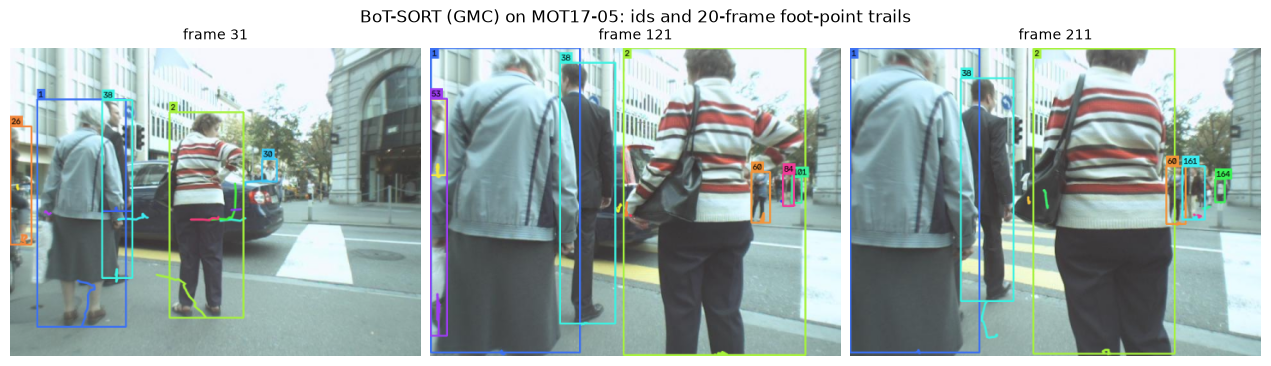

In [12]:
# --- Render a GIF (assets/06_tracking/mot17_05_botsort.gif) and a README thumbnail ---
gif_frames = [tv.render_tracks(seq, pred, t, trail=20, max_side=480) for t in range(1, 241, 3)]
gif_path = cvlab.viz.save_gif(gif_frames, cvlab.io.assets_dir(PROJECT) / "mot17_05_botsort.gif", fps=8)
print(gif_path.relative_to(ROOT), f"{gif_path.stat().st_size / 1e6:.2f} MB")
fig, ax = plt.subplots(figsize=(4.2, 3.2))
ax.imshow(tv.render_tracks(seq, pred, 150, trail=25, max_side=640))
ax.axis("off")
fig.suptitle("BoT-SORT on MOT17-05", fontsize=10)
cvlab.viz.savefig(fig, PROJECT, "thumb", dpi=100)
plt.close(fig)
# Static strip of three GIF frames (the animated GIF itself is embedded in the README).
fig = cvlab.viz.show_images([gif_frames[i] for i in (10, 40, 70)], ncols=3, size=4.2,
                            titles=[f"frame {1 + 3 * i}" for i in (10, 40, 70)],
                            suptitle="BoT-SORT (GMC) on MOT17-05: ids and 20-frame foot-point trails")
plt.show()

## 5. Appearance: can a foundation model re-identify people?

Motion alone cannot resolve every ambiguity: two people crossing, or a person who reappears
after a long occlusion, look the same to a Kalman filter. BoT-SORT can therefore embed every
detection crop into a vector $\mathbf{e}$ and compare it with the track's smoothed embedding
(an exponential moving average). With the cosine distance
$d_{\text{app}} = 1 - \cos(\mathbf{e}_{\text{track}}, \mathbf{e}_{\text{det}})$, Ultralytics
fuses the costs as
$$C = \min\left(C_{\text{IoU}},\ \tfrac{1}{2} d_{\text{app}}\right),$$
where the appearance term is only allowed when the boxes overlap (IoU $\ge 0.5$,
`proximity_thresh`) and the embeddings are similar enough ($\tfrac{1}{2}d_{\text{app}} \le 0.2$,
i.e. cosine similarity $\ge 0.6$, from `appearance_thresh: 0.8`).

Which embedding? We compare two encoders on the *same* crops:

* **yolo26n-reid** (Ultralytics, ONNX): a small network *trained for person
  re-identification*, i.e. to map the same person to nearby vectors and different people far
  apart, whatever the pose or viewpoint.
* **DINOv3 ViT-S/16** (Meta 2025, self-supervised on 1.7 B images, gated on Hugging Face): a
  general-purpose visual backbone. We use its CLS token on $256 \times 128$ crops
  (`dinoreid.DinoV3ReID`, 21 M parameters, fp16). No ReID training at all.

A good ReID embedding separates *same-identity* pairs from *different-identity* pairs. We
sample well-visible GT crops (visibility $\ge 0.7$, height $\ge 60$ px) of MOT17-05, up to 8 per
person, and measure the ROC AUC of the cosine similarity for that binary decision, and the
rank-1 retrieval accuracy (is the most similar crop at least 10 frames away the same person?).

In [13]:
# --- Sample GT person crops of MOT17-05 and embed them with both appearance encoders ---
# Both encoders follow the Ultralytics ReID interface: encoder(bgr_frame, dets_xywh_centre).
import dinoreid  # noqa: E402
from sklearn.metrics import roc_auc_score  # noqa: E402
from transformers.utils import logging as hf_logging  # noqa: E402
from ultralytics.trackers.utils.reid import ReID  # noqa: E402

hf_logging.disable_progress_bar()
rng = np.random.default_rng(0)
cand = scored05[(scored05[:, 8] >= 0.7) & (scored05[:, 5] >= 60)]  # visible and >= 60 px tall
pids, n_seen = np.unique(cand[:, 1], return_counts=True)
sample = np.concatenate([
    cand[cand[:, 1] == p][rng.choice(n, size=min(8, n), replace=False)]
    for p, n in zip(pids, n_seen) if n >= 10  # people with >= 10 usable frames
])
sample = sample[np.argsort(sample[:, 0], kind="stable")]  # frame order = embedding order below
crop_ids, crop_frames = sample[:, 1], sample[:, 0]
encoders = {"yolo26n-reid (ONNX)": ReID(str(WEIGHTS / "yolo26n-reid.onnx"), device="cuda:0"),
            "DINOv3 ViT-S/16 (CLS)": dinoreid.DinoV3ReID(device="cuda")}
emb = {}
for label, enc in encoders.items():
    feats = []
    t0 = time.perf_counter()
    for t in np.unique(crop_frames).astype(int):  # one call per frame, like inside BoT-SORT
        r = sample[crop_frames == t]
        xywh_c = np.column_stack([r[:, 2] + r[:, 4] / 2, r[:, 3] + r[:, 5] / 2, r[:, 4], r[:, 5]])
        feats += enc(cv2.imread(str(seq.frame_path(t))), xywh_c)  # list: one vector per crop
    f = np.stack(feats).astype(np.float64)
    emb[label] = f / np.linalg.norm(f, axis=1, keepdims=True)  # L2-normalise for cosine
    print(f"{label:24s}: {f.shape[0]} crops -> {f.shape[1]}-d embeddings in {time.perf_counter() - t0:.1f} s")
print(f"{len(np.unique(crop_ids))} pedestrians, {len(crop_ids)} crops")

yolo26n-reid (ONNX)     : 408 crops -> 512-d embeddings in 7.9 s


DINOv3 ViT-S/16 (CLS)   : 408 crops -> 384-d embeddings in 7.7 s
51 pedestrians, 408 crops


Now the pairwise cosine similarities. *Positive* pairs are crops of the same person at least
10 frames apart (so they are not near-duplicates); *negative* pairs are crops of different
people. The dashed line is BoT-SORT's appearance gate (cosine similarity 0.6): only pairs to
its right can be matched by appearance.

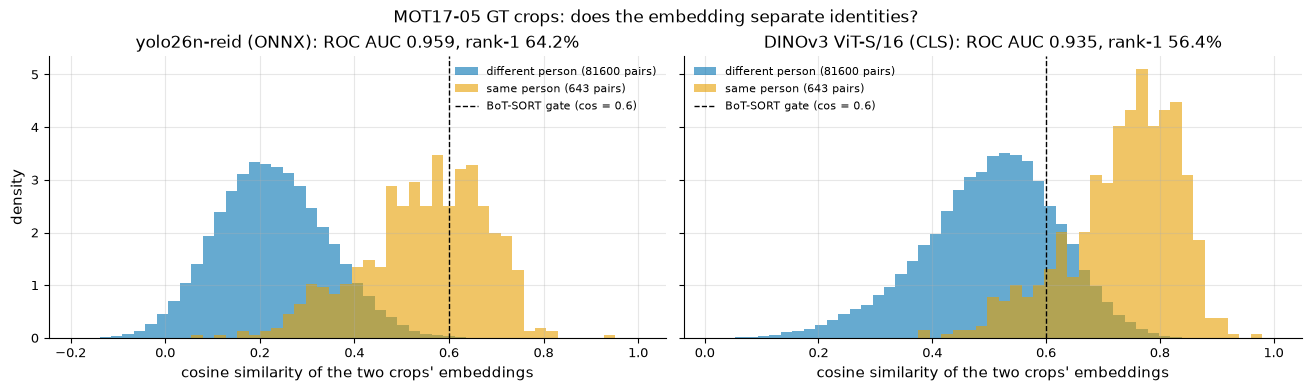

,dim,ROC AUC,rank-1,mean cos same,mean cos different,different pairs above gate,same pairs above gate
encoder,,,,,,,
yolo26n-reid (ONNX),512,0.959,0.642,0.548,0.226,0.001,0.387
DINOv3 ViT-S/16 (CLS),384,0.935,0.564,0.736,0.501,0.204,0.893


In [14]:
# --- Same vs different identity: similarity histograms, ROC AUC and rank-1 retrieval ---
MIN_GAP = 10  # frames
same = crop_ids[:, None] == crop_ids[None, :]
far = np.abs(crop_frames[:, None] - crop_frames[None, :]) >= MIN_GAP
upper = np.triu(np.ones_like(same), k=1)
reid_rows = []
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, (label, e) in zip(axes, emb.items()):
    S = e @ e.T  # cosine similarity matrix (rows are unit vectors)
    pos, neg = S[same & far & upper], S[~same & upper]
    auc = roc_auc_score(np.r_[np.ones(len(pos)), np.zeros(len(neg))], np.r_[pos, neg])
    S_r = np.where(far, S, -np.inf)  # retrieval: ignore the crop itself and its +-10 frames
    rank1 = float(np.mean(crop_ids[np.argmax(S_r, axis=1)] == crop_ids))
    bins = np.linspace(min(neg.min(), pos.min()), 1, 50)
    ax.hist(neg, bins=bins, density=True, alpha=0.6, label=f"different person ({len(neg)} pairs)")
    ax.hist(pos, bins=bins, density=True, alpha=0.6, label=f"same person ({len(pos)} pairs)")
    ax.axvline(0.6, color="k", ls="--", lw=1, label="BoT-SORT gate (cos = 0.6)")
    ax.set_xlabel("cosine similarity of the two crops' embeddings")
    ax.set_title(f"{label}: ROC AUC {auc:.3f}, rank-1 {rank1:.1%}")
    ax.legend(fontsize=8)
    reid_rows.append({"encoder": label, "dim": e.shape[1], "ROC AUC": auc, "rank-1": rank1,
                      "mean cos same": pos.mean(), "mean cos different": neg.mean(),
                      "different pairs above gate": (neg >= 0.6).mean(),
                      "same pairs above gate": (pos >= 0.6).mean()})
axes[0].set_ylabel("density")
fig.suptitle("MOT17-05 GT crops: does the embedding separate identities?")
cvlab.viz.savefig(fig, PROJECT, "reid_embeddings")
plt.show()
reid_df = pd.DataFrame(reid_rows).set_index("encoder")
display(reid_df.round(3))

## Results

The full benchmark was run by

```bash
flock /tmp/cv-gpu.lock python projects/06_tracking/scripts/run_mot_benchmark.py
```

on an RTX 5060 Laptop GPU (8 GB): YOLO26n and YOLO26s detections for **both** sequences
(MOT17-02 and MOT17-05, 1437 frames, 25 498 scored GT boxes), seven trackers on identical
cached detections, end-to-end `model.track()` runs for the speed numbers, and a TrackEval
re-scoring of every tracker file. The small JSON/CSV summaries in
`projects/06_tracking/results/` are loaded here. "COMBINED" rows pool both sequences the way
the MOTChallenge leaderboard does (counts summed, HOTA sub-scores weighted by TP count).

In [15]:
# --- Load the benchmark results (written by scripts/run_mot_benchmark.py) ---
bench = cvlab.io.load_json(RESULTS / "mot_benchmark.json")
gpu = cvlab.io.load_json(RESULTS / "mot_gpu_runs.json")
xchk = cvlab.io.load_json(RESULTS / "trackeval_crosscheck.json")
per = pd.DataFrame(bench["per_sequence"])
comb = pd.DataFrame(bench["combined"])
names = {"sort_scratch": "SORT (scratch)", "bytetrack_no_low": "ByteTrack w/o low",
         "bytetrack": "ByteTrack", "ocsort": "OC-SORT", "botsort_no_gmc": "BoT-SORT no GMC",
         "botsort": "BoT-SORT GMC", "botsort_reid": "BoT-SORT GMC+ReID",
         "botsort_dinov3": "BoT-SORT GMC+DINOv3"}
order = list(names)
print(f"hardware: {gpu['env']['gpu']}, torch {gpu['env']['torch']}")
print(f"TrackEval cross-check: {len(xchk['rows'])} (tracker, sequence) results, "
      f"max |TrackEval - ours| = {xchk['max_abs_diff_percentage_points']:.3f} percentage points")
print(f"model.track() == cached detections + tracker + clipping on all "
      f"{len(bench['e2e_consistency'])} end-to-end runs: {bench['e2e_identical_after_clipping']}")

hardware: NVIDIA GeForce RTX 5060 Laptop GPU, torch 2.11.0+cu128
TrackEval cross-check: 48 (tracker, sequence) results, max |TrackEval - ours| = 0.000 percentage points
model.track() == cached detections + tracker + clipping on all 8 end-to-end runs: True


**Tracker comparison.** With the detector fixed, every difference below is due to
association. HOTA balances detection (DetA) and association (AssA), MOTA is dominated by
FP/FN counts, and IDF1 rewards long, unbroken identities.

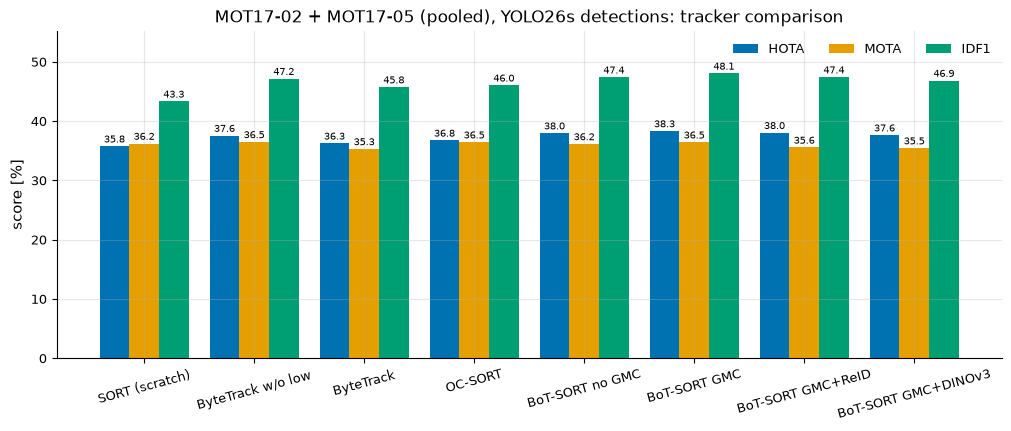

In [16]:
# --- Figure: HOTA / MOTA / IDF1 of every tracker (YOLO26s detections, both sequences pooled) ---
c = comb[comb.detector == "yolo26s"].set_index("tracker").loc[order]
x = np.arange(len(order))
fig, ax = plt.subplots(figsize=(10, 4.2))
for k, metric in enumerate(["HOTA", "MOTA", "IDF1"]):
    bars = ax.bar(x + (k - 1) * 0.27, c[metric], width=0.27, label=metric)
    ax.bar_label(bars, fmt="%.1f", fontsize=7, padding=1)
ax.set_xticks(x, [names[t] for t in order], rotation=15)
ax.set_ylabel("score [%]")
ax.set_ylim(0, max(c[["HOTA", "MOTA", "IDF1"]].max()) * 1.15)
ax.set_title("MOT17-02 + MOT17-05 (pooled), YOLO26s detections: tracker comparison")
ax.legend(ncol=3)
cvlab.viz.savefig(fig, PROJECT, "tracker_comparison")
plt.show()

Per sequence, the most telling number is the count of **identity switches**: the static
camera (MOT17-02) and the moving camera (MOT17-05) stress the trackers differently.
The right panel compares the two detector sizes for the same trackers.

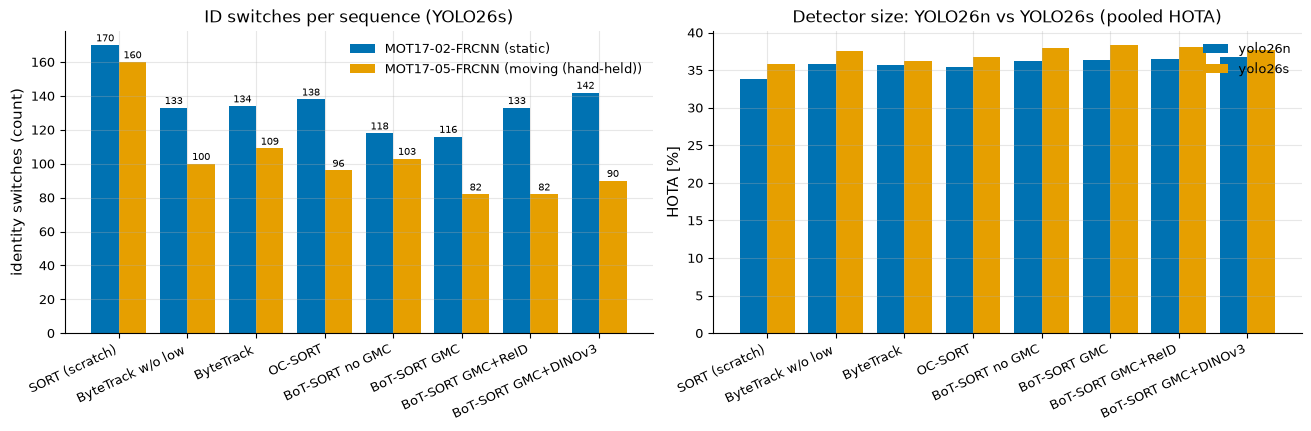

In [17]:
# --- Figure: ID switches per sequence, and detector size (n vs s) vs HOTA ---
p = per[per.detector == "yolo26s"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for k, sname in enumerate(["MOT17-02-FRCNN", "MOT17-05-FRCNN"]):
    v = p[p.seq == sname].set_index("tracker").loc[order, "IDSW"]
    bars = axes[0].bar(x + (k - 0.5) * 0.4, v, width=0.4, label=f"{sname} ({camera[sname]})")
    axes[0].bar_label(bars, fontsize=7, padding=1)
axes[0].set_xticks(x, [names[t] for t in order], rotation=25, ha="right")
axes[0].set_ylabel("identity switches (count)")
axes[0].set_title("ID switches per sequence (YOLO26s)")
axes[0].legend()
for k, det in enumerate(["yolo26n", "yolo26s"]):
    v = comb[comb.detector == det].set_index("tracker").loc[order, "HOTA"]
    axes[1].bar(x + (k - 0.5) * 0.4, v, width=0.4, label=det)
axes[1].set_xticks(x, [names[t] for t in order], rotation=25, ha="right")
axes[1].set_ylabel("HOTA [%]")
axes[1].set_title("Detector size: YOLO26n vs YOLO26s (pooled HOTA)")
axes[1].legend()
cvlab.viz.savefig(fig, PROJECT, "idsw_and_detector")
plt.show()

**Where does the time go?** The detector runs on the GPU; the association runs on the CPU.
Left: per-frame cost of the detector (wall clock including JPEG decoding) next to the tracker
alone. Right: the end-to-end frame rate of `model.track()`.

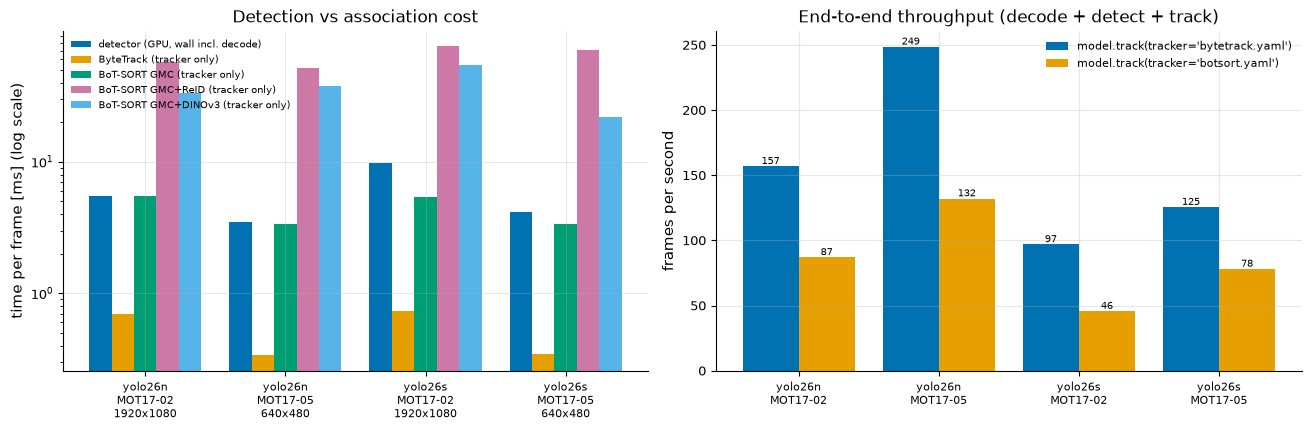

In [18]:
# --- Figure: per-frame latency of detection vs association, and end-to-end FPS ---
det_df = pd.DataFrame(gpu["detector_runs"])
e2e_df = pd.DataFrame(gpu["e2e_runs"])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
labels, det_ms, trk = [], [], {t: [] for t in ["bytetrack", "botsort", "botsort_reid", "botsort_dinov3"]}
for _, r in det_df.iterrows():
    labels.append(f"{r.detector}\n{r.seq[:8]}\n{r.resolution}")
    det_ms.append(r.wall_ms_per_frame)
    for t in trk:
        q = per[(per.detector == r.detector) & (per.seq == r.seq) & (per.tracker == t)]
        trk[t].append(float(q.tracker_ms_per_frame.iloc[0]))
xx = np.arange(len(labels))
axes[0].bar(xx - 0.32, det_ms, width=0.16, label="detector (GPU, wall incl. decode)")
for k, t in enumerate(trk):
    axes[0].bar(xx - 0.16 + 0.16 * k, trk[t], width=0.16, label=f"{names[t]} (tracker only)")
axes[0].set_yscale("log")
axes[0].set_xticks(xx, labels, fontsize=8)
axes[0].set_ylabel("time per frame [ms] (log scale)")
axes[0].set_title("Detection vs association cost")
axes[0].legend(fontsize=7)
for k, t in enumerate(["bytetrack", "botsort"]):
    q = e2e_df[e2e_df.tracker == t]
    bars = axes[1].bar(np.arange(len(q)) + (k - 0.5) * 0.4, q.e2e_fps, width=0.4,
                       label=f"model.track(tracker='{t}.yaml')")
    axes[1].bar_label(bars, fmt="%.0f", fontsize=7)
axes[1].set_xticks(np.arange(len(q)), [f"{d}\n{s[:8]}" for d, s in zip(q.detector, q.seq)], fontsize=8)
axes[1].set_ylabel("frames per second")
axes[1].set_title("End-to-end throughput (decode + detect + track)")
axes[1].legend(fontsize=8)
cvlab.viz.savefig(fig, PROJECT, "latency")
plt.show()

HOTA is an average over localisation thresholds $\alpha$. Plotting $\mathrm{HOTA}_\alpha$
shows how quickly scores fall when tighter boxes are required; the drop at high $\alpha$ is
mostly the amodal-GT vs visible-detection mismatch, which no tracker can fix.

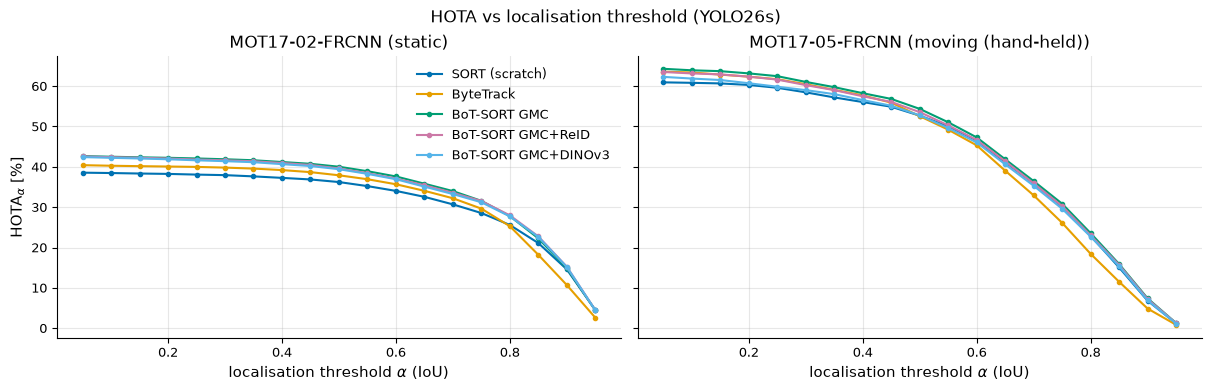

In [19]:
# --- Figure: HOTA as a function of the localisation threshold alpha ---
alphas = np.arange(0.05, 0.99, 0.05)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, sname in zip(axes, ["MOT17-02-FRCNN", "MOT17-05-FRCNN"]):
    for t in ["sort_scratch", "bytetrack", "botsort", "botsort_reid", "botsort_dinov3"]:
        r = per[(per.detector == "yolo26s") & (per.seq == sname) & (per.tracker == t)].iloc[0]
        ax.plot(alphas, 100 * np.asarray(r.HOTA_alpha), marker="o", ms=3, label=names[t])
    ax.set_xlabel(r"localisation threshold $\alpha$ (IoU)")
    ax.set_title(f"{sname} ({camera[sname]})")
axes[0].set_ylabel(r"HOTA$_\alpha$ [%]")
axes[0].legend()
fig.suptitle("HOTA vs localisation threshold (YOLO26s)")
plt.show()

**Summary table.** Pooled scores (both sequences) for both detectors and all tracker
variants. Percentages for the ratio metrics, raw counts for IDSW / Frag / FP / FN / MT / ML.
Tracker FPS is the association step alone (the appearance variants include their GPU
encoder); detector peak VRAM is `torch.cuda.max_memory_allocated` during detection.

In [20]:
# --- Summary table: pooled scores per detector and tracker, with speed and VRAM ---
vram = det_df.groupby("detector").peak_vram_mb.max()
summary = comb.assign(tracker=comb.tracker.map(names)).set_index(["detector", "tracker"])
summary = summary[["HOTA", "DetA", "AssA", "MOTA", "IDF1", "IDSW", "Frag", "CLR_FP", "CLR_FN",
                   "MT", "ML", "tracker_fps"]].rename(columns={"tracker_fps": "tracker FPS (CPU)"})
summary["detector peak VRAM [MiB]"] = [round(vram[d]) for d in summary.index.get_level_values(0)]
display(summary.round(2))

HOTA   DetA   AssA   MOTA   IDF1  IDSW  Frag  \
detector tracker                                                              
yolo26n  SORT (scratch)       33.79  32.66  35.66  33.29  41.29   367   542   
         ByteTrack w/o low    35.78  32.00  40.52  34.65  45.12   222   423   
         ByteTrack            35.68  32.79  39.42  33.39  45.42   205   331   
         OC-SORT              35.44  31.88  39.89  34.18  44.01   215   428   
         BoT-SORT no GMC      36.26  33.12  40.41  33.23  45.06   192   324   
         BoT-SORT GMC         36.34  33.32  40.35  33.48  44.63   192   323   
yolo26s  SORT (scratch)       35.78  35.51  36.68  36.23  43.34   330   555   
         ByteTrack w/o low    37.57  34.70  41.11  36.51  47.17   233   463   
         ByteTrack            36.26  35.37  37.66  35.32  45.75   243   347   
         OC-SORT              36.76  34.69  39.40  36.46  46.05   234   457   
         BoT-SORT no GMC      37.98  36.04  40.73  36.16  47.41   221   335   
         BoT-SORT GMC         38.34  36.34  41.13  36.45  48.06   198   328   
yolo26n  BoT-SORT GMC+ReID    36.43  33.73  39.93  32.67  45.64   231   364   
         BoT-SORT GMC+DINOv3  36.69  34.09  40.31  32.57  45.28   239   371   
yolo26s  BoT-SORT GMC+ReID    38.05  36.77  40.21  35.57  47.43   215   354   
         BoT-SORT GMC+DINOv3  37.64  36.77  39.37  35.46  46.85   232   370   

                              CLR_FP  CLR_FN  MT  ML  tracker FPS (CPU)  \
detector tracker                                                          
yolo26n  SORT (scratch)         2195   14448  32  61            2261.32   
         ByteTrack w/o low      1741   14699  32  66            2522.02   
         ByteTrack              2653   14126  33  60            2200.12   
         OC-SORT                1870   14698  31  65            1238.41   
         BoT-SORT no GMC        2745   14087  35  61            2236.65   
         BoT-SORT GMC           2747   14023  40  58             238.77   
yolo26s  SORT (scratch)         2319   13610  40  51            2119.31   
         ByteTrack w/o low      2054   13902  38  60            2368.32   
         ByteTrack              2921   13327  38  55            2129.05   
         OC-SORT                2122   13845  39  60            1181.80   
         BoT-SORT no GMC        2880   13177  43  55            2160.01   
         BoT-SORT GMC           2937   13069  44  47             240.90   
yolo26n  BoT-SORT GMC+ReID      3355   13581  40  54              18.38   
         BoT-SORT GMC+DINOv3    3434   13521  41  54              28.20   
yolo26s  BoT-SORT GMC+ReID      3439   12775  48  45              13.68   
         BoT-SORT GMC+DINOv3    3490   12735  49  44              32.25   

                              detector peak VRAM [MiB]  
detector tracker                                        
yolo26n  SORT (scratch)                             92  
         ByteTrack w/o low                          92  
         ByteTrack                                  92  
         OC-SORT                                    92  
         BoT-SORT no GMC                            92  
         BoT-SORT GMC                               92  
yolo26s  SORT (scratch)                            170  
         ByteTrack w/o low                         170  
         ByteTrack                                 170  
         OC-SORT                                   170  
         BoT-SORT no GMC                           170  
         BoT-SORT GMC                              170  
yolo26n  BoT-SORT GMC+ReID                          92  
         BoT-SORT GMC+DINOv3                        92  
yolo26s  BoT-SORT GMC+ReID                         170  
         BoT-SORT GMC+DINOv3                       170

### Takeaways

* **The detector sets the ceiling.** The best pipeline (YOLO26s + BoT-SORT with GMC) reaches
  HOTA 38.34 / MOTA 36.45 / IDF1 48.06 pooled over both sequences, and still misses 13 069 of the
  25 498 scored GT boxes (CLR_FN): a COCO detector that was never fine-tuned on MOT17 does not
  find small, crowded or heavily occluded pedestrians, and no association step can recover a
  person who is never detected. Going from YOLO26n to YOLO26s adds 0.6 to 2.0 HOTA points to
  every tracker, about as much as the best association choice adds over our plain SORT
  (35.78 -> 38.34 with YOLO26s).
* **ByteTrack's low-score stage did not pay off with this detector.** Switching it off raised
  pooled HOTA from 36.26 to 37.57 and IDF1 from 45.75 to 47.17 (YOLO26s): the weak boxes cut
  FN (13 902 -> 13 327) but added more FP (2 054 -> 2 921). Section 2 explains why: only
  13.7 % of the boxes with $0.1 \le s < 0.25$ are true positives here. The idea works when the
  low band is mostly occluded people, which depends on the detector's calibration.
* **Camera-motion compensation is what a moving robot needs.** On the hand-held MOT17-05,
  BoT-SORT with GMC vs without: ID switches 103 -> 82, HOTA 44.43 -> 45.45, IDF1
  59.16 -> 61.19. On the static MOT17-02 it changes almost nothing (116 vs 118 switches). GMC
  costs CPU time (tracker-only throughput about 241 instead of 2 160 FPS, pooled), still far
  above the detector's frame rate.
* **Appearance did not help on these short sequences.** With YOLO26s, adding the trained
  ReID model or DINOv3 features to BoT-SORT (GMC) lowered pooled HOTA (38.34 -> 38.05 / 37.64)
  and raised ID switches (198 -> 215 / 232), at 14 / 32 FPS for the tracker; with YOLO26n they
  added only 0.09 / 0.35 HOTA points and also raised ID switches (192 -> 231 / 239). Section 5 shows why DINOv3
  is the weaker choice: with BoT-SORT's default gate, 20.4 % of *different*-person DINOv3 pairs
  look similar enough to match, against 0.1 % for the ReID network (ROC AUC 0.935 vs 0.959).
  Generic features need a recalibrated threshold (exercise 4).
* **Read several metrics.** MOTA hardly separates the trackers (35.32-36.51 pooled with
  YOLO26s) because FN dominate it; IDF1, AssA and the ID-switch count show the association
  differences. Our NumPy metrics match TrackEval to 0.000 percentage points on all 48 results,
  and `model.track()` reproduces "cached detections + tracker" exactly once boxes are clipped
  to the image (clipping alone moves MOTA on MOT17-05 from 45.73 to 44.83).

## Exercises

Solutions are in `projects/06_tracking/solutions/` (they reuse the cached detections in
`runs/06_tracking/dets/`, so run the benchmark script first).

**Exercise 1: tune ByteTrack.** Sweep `track_buffer` (frames a lost track survives) over
`[5, 15, 30, 60, 120]` and `match_thresh` over `[0.6, 0.8, 0.9]` on MOT17-05 with the YOLO26s
detections, and plot IDF1 and ID switches. Which parameter matters more on a moving camera,
and why does a very long buffer eventually hurt?

In [21]:
# --- Exercise 1: sweep ByteTrack's track_buffer and match_thresh ---
# TODO: for each setting build ml.make_tracker(str(CFG_DIR / "bytetrack.yaml"), track_buffer=..., match_thresh=...),
# run ml.run_tracker on `dets`, score with ml.evaluate(gt05, rows, seq.length) and plot IDF1 / IDSW.

**Exercise 2: turn SORT into ByteTrack.** Copy `ml.SimpleSORT` and add a second association
stage: tracks left unmatched after the high-score stage are matched (IoU >= 0.5) to boxes with
$0.1 < s < 0.25$; those boxes may extend tracks but never create new ones. How much of the gap
between SORT and ByteTrack does this single idea close?

In [22]:
# --- Exercise 2: add a low-score association stage to SimpleSORT ---
# TODO: subclass ml.SimpleSORT, override update(), run it on `dets` and compare with the table above.

**Exercise 3: why the protocol matters.** Score the BoT-SORT output with
`ml.evaluate(..., preprocess=False)` (every GT row counts, no distractor removal) and compare
FP, FN and MOTA with the official protocol. Which GT classes cause the difference on MOT17-02?

In [23]:
# --- Exercise 3: evaluate with and without the MOT17 preprocessing ---
# TODO: compare ml.evaluate(gt, rows, n) with ml.evaluate(gt, rows, n, preprocess=False)
# and count the GT rows per class with np.unique(gt[:, 7], return_counts=True).

**Exercise 4: calibrate the appearance gate for DINOv3.** BoT-SORT's `appearance_thresh`
(0.8, i.e. cosine similarity $\ge 0.6$) was chosen for a trained ReID embedding, and section 5
showed that DINOv3 similarities are much higher overall. On **MOT17-02** GT crops (so the test
sequence stays unseen), find the cosine similarity $\cos^*$ that only 1 % of different-person
pairs exceed, set `appearance_thresh` $= (1 + \cos^*)/2$, and re-run BoT-SORT + DINOv3 on
MOT17-05. Does a calibrated gate change HOTA / IDF1 / ID switches?

In [24]:
# --- Exercise 4: calibrate BoT-SORT's appearance gate for DINOv3 embeddings ---
# TODO: embed MOT17-02 GT crops with dinoreid.DinoV3ReID, take np.quantile(cos_different, 0.99),
# then ml.make_tracker(str(CFG_DIR / "botsort_reid.yaml"), device="cuda:0", encoder=enc,
#                      appearance_thresh=(1 + cos_star) / 2) and score it on MOT17-05.